# 2nd round - Step 1: reading and understanding the data

This notebook reads every file of the case study (names unchanged), checks it against the data
dictionary, profiles every column and checks the keys and links between tables. **Nothing is
changed here**: the purpose is to know the data before cleaning it. The same code runs as a script:
`python 01_data_reading.py` (reports in `reports/01_reading/`).

In [1]:
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config as C
import helpers as H

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
print(f"{C.ROUND} - {C.MARKET} - {C.COMPETITION}")import helpers as H

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
print(f"{C.ROUND} - {C.MARKET} - {C.COMPETITION}")

reading = importlib.import_module("01_data_reading")

2nd round - emerging market - IAA AI-Assisted Hackathon 2026 - Part 2


## 1. The files
Identifiers are read as text, dates as dates, and True/False/None columns as nullable booleans.

In [2]:
data = reading.read_all()
pd.DataFrame([{"table": k, "rows": len(v), "columns": v.shape[1]} for k, v in data.items()])

  customers                 135,856 rows x 17 columns
  addresses                 136,914 rows x 16 columns


  weather                   410,742 rows x  9 columns
  claims                      9,258 rows x 12 columns


  policies_motor             47,283 rows x 36 columns
  policies_buildings         27,447 rows x 27 columns
  policies_contents          34,566 rows x 28 columns


  test_motor                 90,521 rows x 35 columns


  test_buildings             52,295 rows x 26 columns
  test_contents              66,247 rows x 27 columns


  sample_submission         209,063 rows x  2 columns
  expenses                        8 rows x  4 columns
  reference_policies             20 rows x 50 columns


,table,rows,columns
0,customers,135856,17
1,addresses,136914,16
2,weather,410742,9
3,claims,9258,12
4,policies_motor,47283,36
5,policies_buildings,27447,27
6,policies_contents,34566,28
7,test_motor,90521,35
8,test_buildings,52295,26
9,test_contents,66247,27


## 2. Columns against the data dictionary
Every column should be in `config.DICTIONARY` (type and meaning), and every dictionary column in the file.

In [3]:
schema = reading.schema_check(data)
print(schema["status"].value_counts().to_string())
schema.loc[schema["status"] != "ok"]

status
ok    289


,table,column,in_dictionary,dictionary_type,dtype_read,status


## 3. Profile of every column
Missing values, distinct values, range and the most frequent values. The full table is `reports/01_reading/column_profile.csv`.

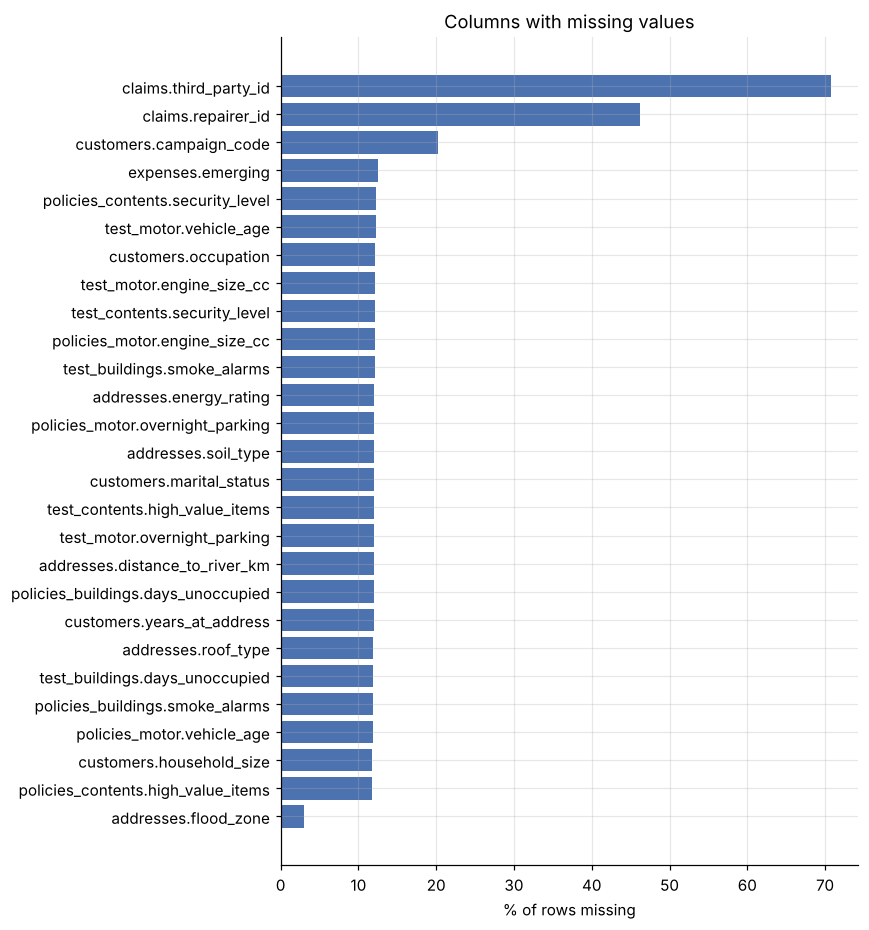

In [4]:
prof = pd.concat([H.profile(df, n) for n, df in data.items()], ignore_index=True)
miss = prof.loc[prof["missing_pct"] > 0, ["table", "column", "missing_pct", "distinct"]]
miss = miss.loc[~miss["table"].isin(["reference_policies"])].sort_values("missing_pct")
fig, ax = plt.subplots(figsize=(8, 0.28 * len(miss) + 1))
ax.barh(miss["table"] + "." + miss["column"], miss["missing_pct"], color="#4C72B0")
ax.set_xlabel("% of rows missing"); ax.set_title("Columns with missing values")
plt.tight_layout(); plt.show()

In [5]:
prof.loc[prof["table"].isin(["policies_motor", "policies_buildings", "policies_contents"]),
         ["table", "column", "dtype", "missing_pct", "distinct", "min", "median", "max", "top_values"]]

,table,column,dtype,missing_pct,distinct,min,median,max,top_values
54,policies_motor,row_id,string,0.0,47283,NaN,NaN,NaN,M00000000 (1); M00000001 (1); M00000002 (1); M00000003 (1); M00000004 (1); M00000005 (1)
55,policies_motor,policy_id,string,0.0,23722,NaN,NaN,NaN,M61105325 (4); M03367245 (4); M51980251 (4); M96948734 (4); M42168510 (4); M54779473 (4)
56,policies_motor,customer_id,string,0.0,23722,NaN,NaN,NaN,23128226 (4); 36316135 (4); 49767091 (4); 38275564 (4); 86896118 (4); 54084415 (4)
57,policies_motor,address_id,string,0.0,23799,NaN,NaN,NaN,A8242647 (10); A9579498 (9); A1021018 (9); A2958263 (8); A3015082 (8); A9830968 (7)
58,policies_motor,period_start,datetime64[s],0.0,728,2023-01-01,NaN,2024-12-29,"2024-01-01 (20,084); 2023-01-01 (17,655); 2024-11-08 (28); 2024-01-02 (26); 2024-04-30 (26); 2024-12-17 (25)"
...,...,...,...,...,...,...,...,...,...
140,policies_contents,days_quote_to_inception,int64,0.0,31,0.0,13.00,30.0,"0 (5,247); 27 (1,063); 22 (1,036); 26 (1,024); 12 (1,018); 8 (1,018)"
141,policies_contents,discount_applied,float64,0.0,3,0.0,0.00,0.1,"0.0 (25,806); 0.05 (8,516); 0.1 (244)"
142,policies_contents,written_premium,float64,0.0,15791,26.62,118.95,573.35,112.3 (10); 88.2 (10); 83.39 (9); 97.54 (9); 98.41 (9); 77.68 (9)
143,policies_contents,customer_service_contacts,int64,0.0,12,0.0,0.00,11.0,"0 (22,451); 1 (8,838); 2 (2,312); 3 (616); 4 (218); 5 (75)"


## 4. Keys and links between tables
Unique keys, every row's customer and address, every claim's policy, weather for every address-year on cover, the 2025 rows against the sample submission.

In [6]:
keys = reading.key_checks(data)
print(f"{int(keys['passed'].sum())} of {len(keys)} checks pass")
keys.loc[~keys["passed"]]

61 of 61 checks pass


,table,check,failures,checked,passed,detail


## 5. What will need cleaning
### 5.1 Exposure against the period dates
The 2025 files define exposure as covered days / 365. Training rows that disagree were recorded in days or on a 360-day basis.

In [7]:
recs = []
for t in [t for t in C.POLICY_TABLES if t.startswith("policies_")] + [t for t in C.POLICY_TABLES if t.startswith("test_")]:
    d = data[t]
    days = (d["period_end"] - d["period_start"]).dt.days + 1
    bad = ~np.isclose(d["exposure"], days / 365, atol=1e-3)
    recs.append({"table": t, "rows": len(d), "exposure != days/365": int(bad.sum()),
                 "of which in days": int(np.isclose(d.loc[bad, "exposure"], days[bad]).sum()),
                 "of which days/360": int(np.isclose(d.loc[bad, "exposure"], days[bad] / 360, atol=1e-3).sum())})
pd.DataFrame(recs)

,table,rows,exposure != days/365,of which in days,of which days/360
0,policies_motor,47283,249,47,202
1,policies_buildings,27447,152,33,119
2,policies_contents,34566,194,34,160
3,test_motor,90521,0,0,0
4,test_buildings,52295,0,0,0
5,test_contents,66247,0,0,0


### 5.2 Sums insured
On a log scale the unit errors stand apart: values hundreds to thousands of times the median (recorded in units instead of thousands), with nothing between 10x and 100x. Anything above 100x the median (dashed line) is rescaled in step 2.

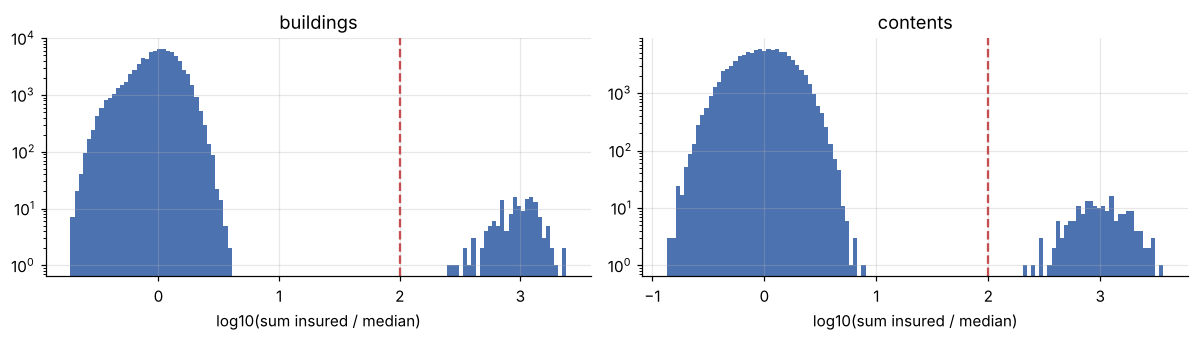

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, line in zip(axes, ["buildings", "contents"]):
    si = pd.concat([data[f"policies_{line}"]["sum_insured"], data[f"test_{line}"]["sum_insured"]])
    r = np.log10(si / si.median())
    ax.hist(r, bins=120, color="#4C72B0")
    ax.set_yscale("log"); ax.set_xlabel("log10(sum insured / median)"); ax.set_title(line)
    ax.axvline(np.log10(C.SI_UNIT_ERROR_RATIO), color="#C44E52", ls="--")
plt.tight_layout(); plt.show()

### 5.3 Identifiers
All-digit customer ids must have 8 digits. Shorter ones lost their leading zeros when stored as numbers.

In [9]:
for t in C.POLICY_TABLES:
    l = data[t]["customer_id"].str.len().value_counts().sort_index()
    print(f"{t:<20} customer_id lengths: {({int(k): int(v) for k, v in l.items()})}")

policies_motor       customer_id lengths: {8: 47283}
policies_buildings   customer_id lengths: {8: 27447}
policies_contents    customer_id lengths: {8: 34566}
test_motor           customer_id lengths: {8: 90521}
test_buildings       customer_id lengths: {8: 52295}
test_contents        customer_id lengths: {8: 66247}


### 5.4 Claims
Claims by loss year and peril; claims stored twice under a second `claim_id`; reporting delays (the slow perils are the ones still largely unreported at 31 December 2024).

In [10]:
cl = data["claims"]
display(pd.crosstab([cl["line"], cl["peril"]], cl["loss_date"].dt.year))
fields = [c for c in cl.columns if c != "claim_id"]
dup = cl.duplicated(fields, keep=False)
id_len = cl.loc[dup, "claim_id"].str.len().value_counts().sort_index()
print(f"claims identical in every field but the claim_id: {int(dup.sum())} records "
      f"(id lengths: {({int(k): int(v) for k, v in id_len.items()})})")
if dup.any():
    first = cl.loc[dup].sort_values(fields).head(4)
    display(first)
delay = (cl["report_date"] - cl["loss_date"]).dt.days
cl.assign(delay=delay).groupby(["line", "peril"])["delay"].describe(percentiles=[0.5, 0.9, 0.99])[["count", "50%", "90%", "99%", "max"]]

loss_date                    2021  2022  2023  2024
line      peril                                    
buildings accidental_damage     0     0    55    67
          escape_of_water       0     0   131   137
          fire                  0     0    49    21
          flood                 0     1    42    38
          storm                 1     1   210   254
          subsidence            0     0    32    20
contents  accidental_damage     0     0   169   171
          escape_of_water       1     0    86    85
          flood                 0     0    51    35
          theft                 0     4   193   221
motor     bodily_injury         1     0   266   183
          glass_hail            1     4   601   744
          own_damage            1     8  1393  1310
          theft                 0     1   199   208
          third_party_prop      1     9  1149  1104

claims identical in every field but the claim_id: 0 records (id lengths: {})


count   50%    90%     99%    max
line      peril                                                
buildings accidental_damage   122.0   8.0   23.9   37.79   62.0
          escape_of_water     268.0   9.0   39.3   96.24  419.0
          fire                 70.0   4.0   12.1   19.31   20.0
          flood                81.0   8.0   25.0  135.40  493.0
          storm               466.0   8.0   24.5   51.35  483.0
          subsidence           52.0  55.5  185.3  273.60  294.0
contents  accidental_damage   340.0   7.0   22.0   48.00   88.0
          escape_of_water     172.0  12.0   37.7   83.35  481.0
          flood                86.0   9.0   23.5   37.45   40.0
          theft               418.0   4.0   13.0  441.39  542.0
motor     bodily_injury       450.0  99.0  318.1  567.38  653.0
          glass_hail         1350.0   6.0   18.0   37.51  548.0
          own_damage         2712.0   7.0   24.0   54.78  535.0
          theft               408.0   4.0   13.0   25.93  490.0
          third_party_prop   2263.0  14.0   46.0  103.38  565.0

Largest claim of each peril against the next one: a claim far above the rest with a small paid amount is a reserve typed with an extra digit.

In [11]:
top = (cl.sort_values("incurred_to_date", ascending=False).groupby(["line", "peril"])
       .head(2).groupby(["line", "peril"])["incurred_to_date"].apply(list))
pd.DataFrame({"largest": top.str[0], "second": top.str[1], "ratio": top.str[0] / top.str[1]}).round(1)

largest    second  ratio
line      peril                                       
buildings accidental_damage    3952.2    3769.3    1.0
          escape_of_water     41892.5   24178.0    1.7
          fire               361092.6  339948.9    1.1
          flood              143434.0  131398.8    1.1
          storm               17966.0   16622.8    1.1
          subsidence          60017.0   49476.5    1.2
contents  accidental_damage    6056.0    4966.3    1.2
          escape_of_water     14516.3   12739.1    1.1
          flood               50884.8   44269.3    1.1
          theft               19967.9   18990.8    1.1
motor     bodily_injury      155654.8  136767.2    1.1
          glass_hail           5072.9    5041.9    1.0
          own_damage          12819.8   12630.6    1.0
          theft               29218.6   23460.8    1.2
          third_party_prop    39709.1   15651.8    2.5

### 5.5 Driver history
The age at first licence (driver age - years licensed) cannot be below 17. In the 1st round some rows break this, and the same policy's other years show the true value. The 2nd round has age bands only.

In [12]:
m = data["policies_motor"]
if "driver_age" in m:
    afl = m["driver_age"] - m["years_licensed"]
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.hist(afl, bins=range(0, 30), color="#4C72B0"); ax.axvline(C.MIN_LICENCE_AGE, color="#C44E52", ls="--")
    ax.set_yscale("log"); ax.set_xlabel("age at first licence"); plt.tight_layout(); plt.show()
    print(f"rows with a licence before {C.MIN_LICENCE_AGE}: {int((afl < C.MIN_LICENCE_AGE).sum()):,}")
f = m["ncb_years"] > m["years_licensed"]
band = m["driver_age_band"] if "driver_age_band" in m else pd.cut(m["driver_age"], [16, 24, 34, 49, 64, 120])
print("no-claims bonus longer than the licence, share by driver age:")
print(f.groupby(band).mean().round(3).to_string())

no-claims bonus longer than the licence, share by driver age:
driver_age_band
17-24    0.375
25-34    0.452
35-49    0.019
50-64    0.000
65+      0.000


### 5.6 Weather
One row per address and year, including 2025. The 2025 values partly lie outside the training years' range.

In [13]:
w = data["weather"]
w.groupby("year")[[c for c in C.WEATHER_VARS]].mean().round(3)

,hail_days,wind_exposure_index,freezing_days,dry_summer_index,wildfire_index,rainfall_mm,mean_temperature_c
year,,,,,,,
2023,13.974,4.681,21.018,0.679,0.503,1380.810,15.295
2024,17.081,5.413,17.490,0.712,0.549,1375.087,15.777
2025,11.411,5.114,28.863,0.605,0.528,1250.664,14.223


## 6. Summary
The issues found here are fixed in step 2 (`02_data_cleaning`), each with a logged rule; the reports of this step are in `reports/01_reading/` (`schema_check.csv`, `column_profile.csv`, `key_checks.csv`, `data_dictionary.md`).